# Catch Probability EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
import shap

import os
import requests
import json

import math

## modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

from pygam import LinearGAM, s, te

import xgboost as xgb

import statsmodels.api as sm

import arviz_plots as azp

pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:.6f}".format)

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.parallel")

In [2]:
azp.style.use("arviz-darkgrid")

## data preproc + eda

In [3]:
fielding_all_situations = pd.read_csv('data/processed_positioning/all_situations.csv')

fielding_lhh_000_no_shift = pd.read_csv('data/processed_positioning/lhh_000_no_shift.csv')
fielding_lhh_000_shift = pd.read_csv('data/processed_positioning/lhh_000_shift.csv')
fielding_lhh_001_no_shift = pd.read_csv('data/processed_positioning/lhh_001_no_shift.csv')
fielding_lhh_001_shift = pd.read_csv('data/processed_positioning/lhh_001_shift.csv')
fielding_lhh_else_no_shift = pd.read_csv('data/processed_positioning/lhh_else_no_shift.csv')
fielding_lhh_else_shift = pd.read_csv('data/processed_positioning/lhh_else_shift.csv')

fielding_rhh_000_no_shift = pd.read_csv('data/processed_positioning/rhh_000_no_shift.csv')
fielding_rhh_000_shift = pd.read_csv('data/processed_positioning/rhh_000_shift.csv')
fielding_rhh_001_no_shift = pd.read_csv('data/processed_positioning/rhh_001_no_shift.csv')
fielding_rhh_001_shift = pd.read_csv('data/processed_positioning/rhh_001_shift.csv')
fielding_rhh_else_no_shift = pd.read_csv('data/processed_positioning/rhh_else_no_shift.csv')
fielding_rhh_else_shift = pd.read_csv('data/processed_positioning/rhh_else_shift.csv')

statcast_data = pd.read_parquet('../predictive_stuff_model/data/statcast.parquet')
batted_balls = statcast_data[statcast_data['description'] == 'hit_into_play'].reset_index(drop=True)

In [4]:
# maps the venue to each batted ball to have the correct associated stadium

with open('data/venue_cache.json', 'r') as f:
    raw_cache = json.load(f)
venue_ids = {int(game_pk): info['venue_id'] for game_pk, info in raw_cache.items()}
venue_names = {int(game_pk): info['venue_name'] for game_pk, info in raw_cache.items()}

batted_balls['venue_id'] = batted_balls['game_pk'].map(venue_ids)
batted_balls['venue_name'] = batted_balls['game_pk'].map(venue_names)
batted_balls['venue_name'] = batted_balls['venue_name'].apply(lambda x: 'Rate Field' if x=='Guaranteed Rate Field' 
                                                              else 'American Family Field' if x=='Miller Park'
                                                              else 'T-Mobile Park' if x=='Safeco Field'
                                                              else 'Daikin Park' if x=='Minute Maid Park'
                                                              else 'Oracle Park' if x=='AT&T Park'
                                                              else 'Journey Bank Ballpark' if x=='Muncy Bank Ballpark'
                                                              else 'loanDepot park' if x=='Marlins Park'
                                                              else 'Truist Park' if x=='SunTrust Park'
                                                              else x)

In [5]:
batted_balls[['hc_x', 'hc_y', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az']].isna().sum()

hc_x                7505
hc_y                7505
hit_distance_sc    24913
launch_speed        6060
launch_angle        5792
effective_speed     2700
vx0                 1543
vy0                 1543
vz0                 1543
ax                  1543
ay                  1543
az                  1543
dtype: int64

In [6]:
batted_balls[['hc_x', 'hc_y', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az']].isna().sum() / batted_balls.shape[0]

hc_x              0.008199
hc_y              0.008199
hit_distance_sc   0.027216
launch_speed      0.006620
launch_angle      0.006327
effective_speed   0.002950
vx0               0.001686
vy0               0.001686
vz0               0.001686
ax                0.001686
ay                0.001686
az                0.001686
dtype: float64

In [7]:
batted_balls[['hc_x', 'hc_y', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az']].dtypes

hc_x               Float64
hc_y               Float64
hit_distance_sc      Int64
launch_speed       Float64
launch_angle         Int64
effective_speed    Float64
vx0                Float64
vy0                Float64
vz0                Float64
ax                 Float64
ay                 Float64
az                 Float64
dtype: object

In [8]:
## we'll just get rid of the 915,375 batted balls that have a missing hc_x/hc_y/ev/la/velo

batted_balls = batted_balls[(~batted_balls['hc_x'].isna()) & 
                            (~batted_balls['launch_speed'].isna()) & 
                            (~batted_balls['launch_angle'].isna()) & 
                            (~batted_balls['effective_speed'].isna()) & 
                            (~batted_balls['vx0'].isna())
                            ].reset_index(drop=True)

## fixing dtypes
batted_balls['hit_distance_sc'] = batted_balls['hit_distance_sc'].astype(float)
batted_balls['launch_angle'] = batted_balls['launch_angle'].astype(float)
batted_balls['venue_id'] = batted_balls['venue_id'].astype(int)

batted_balls['on_1b'] = batted_balls['on_1b'].notna().astype(int)
batted_balls['on_2b'] = batted_balls['on_2b'].notna().astype(int)
batted_balls['on_3b'] = batted_balls['on_3b'].notna().astype(int)

In [9]:
batted_balls['of_fielding_alignment'].value_counts()

of_fielding_alignment
Standard          845922
Strategic          52089
4th outfielder       685
Name: count, dtype: int64

In [10]:
batted_balls['if_fielding_alignment'].value_counts()

if_fielding_alignment
Standard         583579
Infield shift    140990
Infield shade    108488
Strategic         65639
Name: count, dtype: int64

* 4th outfielder only existed on plays pre-2023 before the shift ban was implemented -> for those we'll use the shift df based on the handedness of the batter
* Infield shift only existed on plays pre-2023 before the shift ban was implemented

In [11]:
# matching the fielding pos from statcast to the game to have player initial coords
# even though it's not the "true" initial pos, the average based on some filters at least provides a good proxy
# using the `avg_norm_start_distance` and `avg_norm_start_angle`, we can use polar coords to figure out the actual intial pos

def adding_polar_coords(df):
    """
    using the distance from home plate and the angle from home plate for the fielder's pos, 
    we can use polar coords to find the estimated initial coord of the player 
    """
    team_map = {"Athletics": "ATH", 
                "Braves": "ATL", 
                "D-backs": "AZ", 
                "Orioles": "BAL", 
                "Red Sox": "BOS", 
                "Cubs": "CHC", 
                "Reds": "CIN", 
                "Guardians": "CLE", 
                "Rockies": "COL", 
                "White Sox": "CWS", 
                "Tigers": "DET", 
                "Astros": "HOU", 
                "Royals": "KC", 
                "Angels": "LAA", 
                "Dodgers": "LAD", 
                "Marlins": "MIA", 
                "Brewers": "MIL", 
                "Twins": "MIN", 
                "Mets": "NYM", 
                "Yankees": "NYY", 
                "Phillies": "PHI", 
                "Pirates": "PIT", 
                "Padres": "SD", 
                "Mariners": "SEA", 
                "Giants": "SF", 
                "Cardinals": "STL", 
                "Rays": "TB", 
                "Rangers": "TEX", 
                "Blue Jays": "TOR", 
                "Nationals": "WSH",
                }
    pos_code = {'C': 2, '1B': 3, '2B': 4, '3B': 5, 'SS': 6, 'LF': 7, 'CF': 8, 'RF': 9}
    df = df.copy()
    df['X_fielder_coord'] = df['avg_norm_start_distance'] * np.cos((90 - df['avg_norm_start_angle']) * (np.pi/180))
    df['Y_fielder_coord'] = df['avg_norm_start_distance'] * np.sin((90 - df['avg_norm_start_angle']) * (np.pi/180))
    df['fld_name_display_club'] = df['fld_name_display_club'].map(team_map)
    df['position'] = df['position'].map(pos_code)
    return df

## applies the func
relevant_fielder_cols = ['name_fielder', 'fielder_id', 'fld_name_display_club', 'season', 'position', 'X_fielder_coord', 'Y_fielder_coord']
fielding_all_situations = adding_polar_coords(fielding_all_situations)[relevant_fielder_cols]

## adds the team id of who is fielding at that given point in time
batted_balls['fielding_team'] = np.where(batted_balls['inning_topbot'] == 'Top', batted_balls['home_team'], batted_balls['away_team'])

batted_balls['runners_on'] = batted_balls[['on_1b', 'on_2b', 'on_3b']].sum(axis=1)
batted_balls['base_state'] = np.where(batted_balls['runners_on'] == 0, '000', 
                                      np.where((batted_balls['on_1b'] == 1) & 
                                               (batted_balls['on_2b'] == 0) & 
                                               (batted_balls['on_3b'] == 0), '001', 'else')
                                      )

## stores the situation positioning dfs
fielding_dfs = {('L', '000', False): adding_polar_coords(fielding_lhh_000_no_shift)[relevant_fielder_cols], 
                ('L', '000', True): adding_polar_coords(fielding_lhh_000_shift)[relevant_fielder_cols], 
                ('L', '001', False): adding_polar_coords(fielding_lhh_001_no_shift)[relevant_fielder_cols], 
                ('L', '001', True): adding_polar_coords(fielding_lhh_001_shift)[relevant_fielder_cols], 
                ('L', 'else', False): adding_polar_coords(fielding_lhh_else_no_shift)[relevant_fielder_cols], 
                ('L', 'else', True): adding_polar_coords(fielding_lhh_else_shift)[relevant_fielder_cols], 
                
                ('R', '000', False): adding_polar_coords(fielding_rhh_000_no_shift)[relevant_fielder_cols], 
                ('R', '000', True): adding_polar_coords(fielding_rhh_000_shift)[relevant_fielder_cols], 
                ('R', '001', False): adding_polar_coords(fielding_rhh_001_no_shift)[relevant_fielder_cols], 
                ('R', '001', True): adding_polar_coords(fielding_rhh_001_shift)[relevant_fielder_cols], 
                ('R', 'else', False): adding_polar_coords(fielding_rhh_else_no_shift)[relevant_fielder_cols], 
                ('R', 'else', True): adding_polar_coords(fielding_rhh_else_shift)[relevant_fielder_cols],
                }

In [12]:
infield_pos = [2, 3, 4, 5, 6]
outfield_pos = [7, 8, 9]
if_shift_vals = ['Infield shift', 'Infield shade', 'Strategic']
of_shift_vals = ['Strategic', '4th outfielder']
batted_balls['if_shifted'] = batted_balls['if_fielding_alignment'].isin(if_shift_vals)
batted_balls['of_shifted'] = batted_balls['of_fielding_alignment'].isin(of_shift_vals)

In [13]:
# condition-based merging the fielder's coords onto the batted_ball dataset

positioning_conditions = []
for (stand, base_state, if_shifted, of_shifted), pos_cond in batted_balls.groupby(['stand', 'base_state', 'if_shifted', 'of_shifted']):
    ## grabs the conditions for the positioning
    if_fielding_df = fielding_dfs.get((stand, base_state, if_shifted))
    of_fielding_df = fielding_dfs.get((stand, base_state, of_shifted))

    ## merging the infielder coords
    for pos in range(2, 7):
        fielder_coords_to_merge = (if_fielding_df[if_fielding_df['position'] == pos]
                                   .rename(columns={'fielder_id': f'fielder_{pos}', 
                                                    'name_fielder': f'fielder_{pos}_name', 
                                                    'X_fielder_coord': f'fielder_{pos}_x', 
                                                    'Y_fielder_coord': f'fielder_{pos}_y',})
                                   .drop(columns=['position']))
        pos_cond = (pos_cond
                 .merge(fielder_coords_to_merge, left_on=['game_year', 'fielding_team', f'fielder_{pos}'], 
                        right_on=['season', 'fld_name_display_club', f'fielder_{pos}'], how='left',)
                 .drop(columns=['season', 'fld_name_display_club'], errors='ignore')
                 )

    ## merging the outfielder coords
    for pos in range(7, 10):
        fielder_coords_to_merge = (of_fielding_df[of_fielding_df['position'] == pos]
                                   .rename(columns={'fielder_id': f'fielder_{pos}', 
                                                    'name_fielder': f'fielder_{pos}_name', 
                                                    'X_fielder_coord': f'fielder_{pos}_x', 
                                                    'Y_fielder_coord': f'fielder_{pos}_y',})
                                   .drop(columns=['position'])
                                   )
        pos_cond = (pos_cond
                 .merge(fielder_coords_to_merge, left_on=['game_year', 'fielding_team', f'fielder_{pos}'], 
                        right_on=['season', 'fld_name_display_club', f'fielder_{pos}'], how='left',)
                 .drop(columns=['season', 'fld_name_display_club'], errors='ignore')
                 )

    positioning_conditions.append(pos_cond)

batted_balls = pd.concat(positioning_conditions, ignore_index=True)
batted_balls['if_shifted'] = batted_balls['if_shifted'].astype(int)
batted_balls['of_shifted'] = batted_balls['of_shifted'].astype(int)

In [14]:
batted_balls = batted_balls[['game_pk', 'game_year', 'game_date', 'description', 'events', 'bb_type', 'p_throws', 'player_name', 'batter', 'stand',
                            'release_speed', 'release_pos_x', 'release_pos_y', 'release_pos_z', 'release_extension',
                            'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az', 'plate_x', 'plate_z', 'on_1b', 'on_2b', 'on_3b', 'runners_on', 'base_state',
                            'launch_speed', 'launch_angle', 'effective_speed', 'hit_distance_sc', 'hc_x', 'hc_y', 'hit_location',
                            'if_fielding_alignment', 'of_fielding_alignment', 'if_shifted', 'of_shifted', 'fielding_team', 
                            'fielder_3_name', 'fielder_3', 'fielder_3_x', 'fielder_3_y', 
                            'fielder_4_name', 'fielder_4', 'fielder_4_x', 'fielder_4_y',
                            'fielder_5_name', 'fielder_5', 'fielder_5_x', 'fielder_5_y',
                            'fielder_6_name', 'fielder_6', 'fielder_6_x', 'fielder_6_y',
                            'fielder_7_name', 'fielder_7', 'fielder_7_x', 'fielder_7_y',
                            'fielder_8_name', 'fielder_8', 'fielder_8_x', 'fielder_8_y',
                            'fielder_9_name', 'fielder_9', 'fielder_9_x', 'fielder_9_y',
                            'venue_id', 'venue_name',
                            ]]

In [15]:
# fills the missing names of the fielders

def get_name(id):
    """
    A get function to find the name of each player based on their mlb id using MLB's Stats API
    """
    url = f"https://statsapi.mlb.com/api/v1/people/{id}"
    r = requests.get(url).json()
    name = [r['people'][0]['fullName']][0]
    return name

## gathers all of the unique missing pos ids
missing_ids = set()
for pos in range(3, 10):
    mask = batted_balls[f'fielder_{pos}_name'].isna()
    unique_ids_for_pos = batted_balls.loc[mask, f'fielder_{pos}'].dropna().unique()
    missing_ids.update(unique_ids_for_pos)

id_to_name_map = {player_id: get_name(player_id) for player_id in missing_ids}

## fills the missing vals across all the cols using the dicts
for pos in range(3, 10):
    col_name = f'fielder_{pos}_name'
    col_id = f'fielder_{pos}'    
    batted_balls[col_name] = batted_balls[col_name].fillna(batted_balls[col_id].map(id_to_name_map))

In [16]:
# maps the events to a more general outcome - basically turns all the niche events to just be outs if they're outs 
## we also only care about batted balls where the outfielder had an opportunity to catch the ball - i.e., no grounders

events_dict = {'single': 'single', 'double': 'double', 'triple': 'triple', 'home_run': 'home_run', \
               'field_out': 'out', 'force_out': 'out', 'grounded_into_double_play': 'out', \
               'sac_fly': 'out', 'field_error': 'error', 'sac_bunt': 'out', 'double_play': 'out', \
               'fielders_choice': 'error', 'fielders_choice_out': 'out', 'sac_fly_double_play': 'out', \
               'triple_play': 'out', 'sac_bunt_double_play': 'out', 'catcher_interf': 'error',
               }
batted_balls['events'] = batted_balls['events'].map(events_dict)
batted_balls = batted_balls[batted_balls['bb_type'] != 'ground_ball'].reset_index(drop=True).copy()

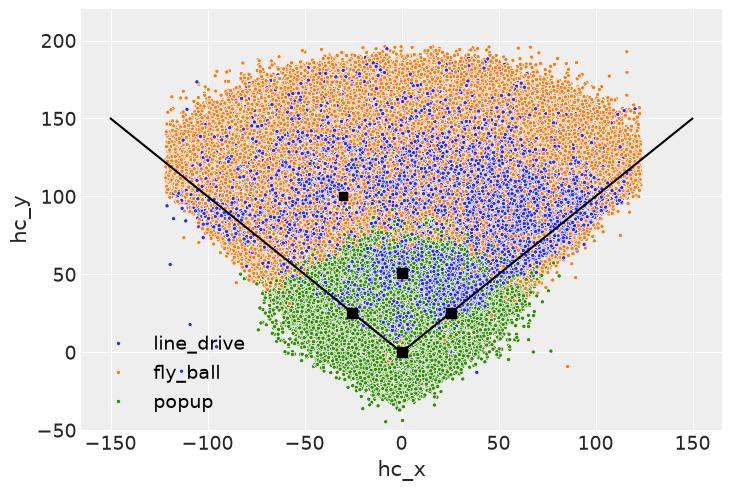

In [17]:
hc_coords = batted_balls.copy()
hc_coords['hc_y'] = hc_coords['hc_y'] * -1
hc_coords['hc_y'] = 198.27 + hc_coords['hc_y']
hc_coords['hc_x'] = 125.42 - hc_coords['hc_x']

## the foul lines to be visualized
lf_x_values = np.linspace(0, -150)
lf_foul_line = -lf_x_values
rf_x_values = np.linspace(0, 150)
rf_foul_line = rf_x_values

## the coords of each base
base_xy = 36 * np.sin(np.radians(45)) 
bases_x = [0, base_xy, 0, -base_xy]
bases_y = [0, base_xy, np.sqrt(36**2 + 36**2), base_xy]

plt.figure()
sns.scatterplot(data=hc_coords[(~hc_coords['hc_x'].isna()) & (~hc_coords['hc_y'].isna())], x='hc_x', y='hc_y', hue='bb_type', marker='.')
plt.plot(0, 0, 'ks',)
plt.plot(lf_x_values, lf_foul_line, c='black',)
plt.plot(rf_x_values, rf_foul_line, c='black')
plt.plot(-30, 100, 'ks')
plt.scatter(bases_x, bases_y, color='black', marker='s', s=50, zorder=5)
plt.ylim(-50, 220)
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

In [18]:
(90+np.degrees(np.arctan(-40/-0.1)))*-1

np.float64(-179.8567608496317)

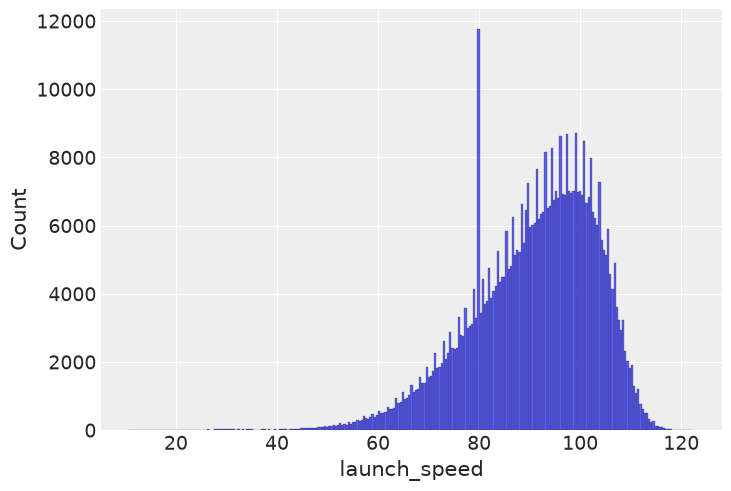

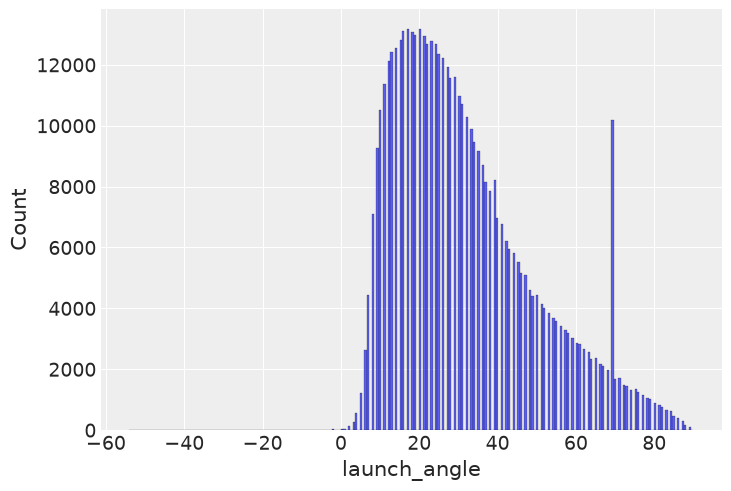

In [19]:
plt.figure()
sns.histplot(data=batted_balls, x='launch_speed')
plt.show()

plt.figure()
sns.histplot(data=batted_balls, x='launch_angle')
plt.show()

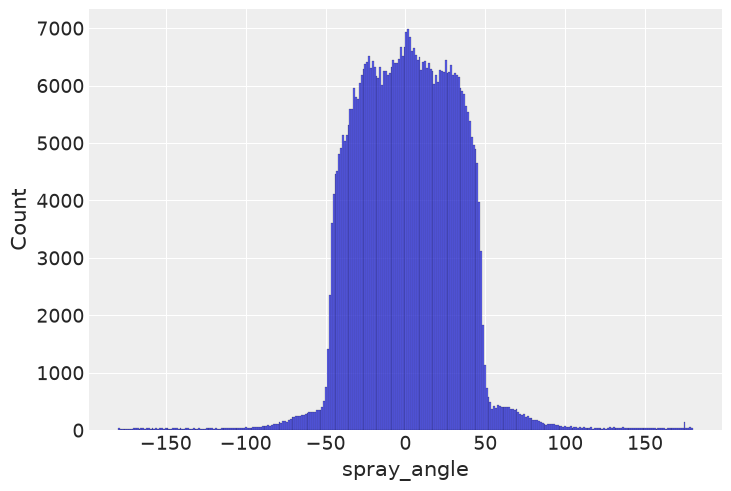

In [20]:
# estimating spray angle using hc_x, hc_y
## after re-orienting hc_x and hc_y to look like the actual field - rather than what it is naturally - we can use the coords to estimate the spray angle
## spray angle is the angle between the (hc_x, hc_y) coord and the reference coord - home plate - (0, 0)
## we can re-orient spray angle itself as well by making 0º be the angle towards second base - rather than 90º

batted_balls['hc_y'] = batted_balls['hc_y'] * -1
batted_balls['hc_y'] = 198.27 + batted_balls['hc_y'] ## re-orienting the y-axis where 198.27 is the original y-coord for home plate
batted_balls['hc_x'] = batted_balls['hc_x'] - 125.42 ## re-orienting the x-axis where 125.42 is the original x-coord for home plate
# batted_balls['hc_x'] = batted_balls['hc_x'] * 0.75

batted_balls['spray_angle'] = np.where((batted_balls['hc_y'] < 0) & (batted_balls['hc_x'] < 0), \
                                       -(90 + np.degrees(np.arctan(batted_balls['hc_y'] / batted_balls['hc_x']))), \
                                        (90 - np.degrees(np.arctan2(batted_balls['hc_y'], batted_balls['hc_x']))))

plt.figure()
sns.histplot(data=batted_balls, x='spray_angle')
plt.show()

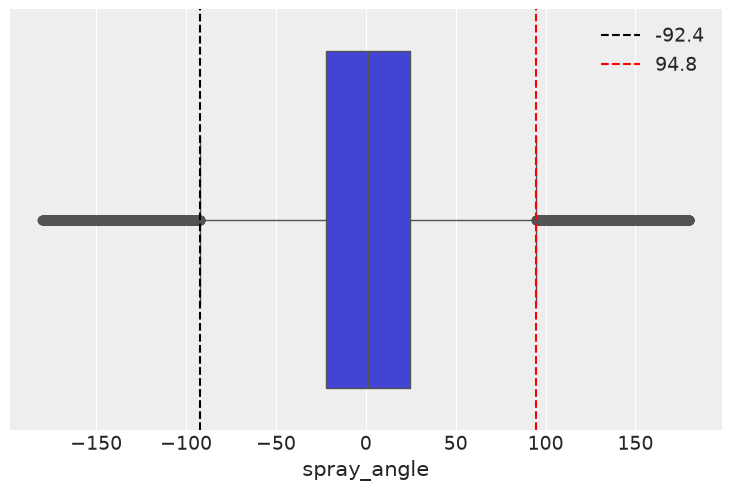

count   511293.000000
mean         1.339008
std         31.937237
min       -179.938036
25%        -22.221287
50%          1.226929
75%         24.578930
max        179.944238
Name: spray_angle, dtype: float64

In [21]:
spray_angle_iqr = (batted_balls['spray_angle'].describe()['75%'] - batted_balls['spray_angle'].describe()['25%'])
spray_angle_cutoffs = (batted_balls['spray_angle'].describe()['25%'] - 1.5*spray_angle_iqr, \
                       batted_balls['spray_angle'].describe()['75%'] + 1.5*spray_angle_iqr)

plt.figure()
sns.boxplot(data=batted_balls, x='spray_angle')
plt.axvline(x=spray_angle_cutoffs[0], linestyle='--', color='black', label=f'{spray_angle_cutoffs[0]:.1f}')
plt.axvline(x=spray_angle_cutoffs[1], linestyle='--', color='red', label=f'{spray_angle_cutoffs[1]:.1f}')
plt.legend()
plt.show()

batted_balls['spray_angle'].describe()

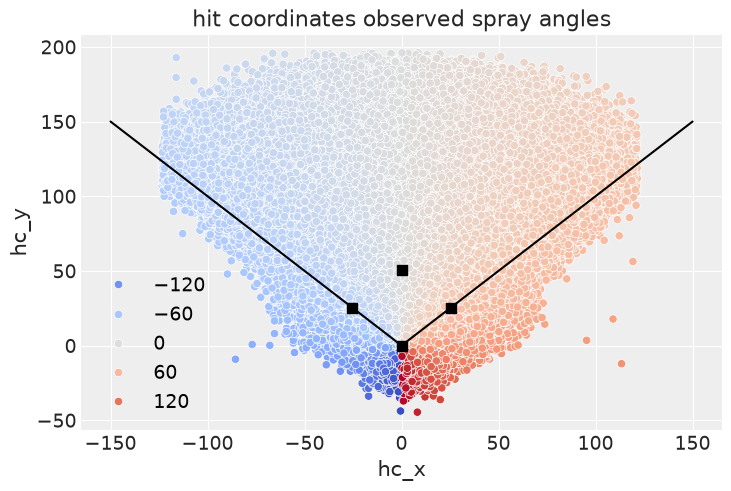

In [22]:
## the foul lines to be visualized
lf_x_values = np.linspace(0, -150)
lf_foul_line = -lf_x_values
rf_x_values = np.linspace(0, 150)
rf_foul_line = rf_x_values

## the coords of each base
base_xy = 36 * np.sin(np.radians(45)) 
bases_x = [0, base_xy, 0, -base_xy]
bases_y = [0, base_xy, np.sqrt(36**2 + 36**2), base_xy]

plt.figure()
sns.scatterplot(data=batted_balls, x='hc_x', y='hc_y', hue='spray_angle', palette='coolwarm')
plt.plot(0, 0, 'ks')
plt.plot(lf_x_values, lf_foul_line, c='black',)
plt.plot(rf_x_values, rf_foul_line, c='black')
plt.scatter(bases_x, bases_y, color='black', marker='s', s=50, zorder=5)
plt.title('hit coordinates observed spray angles')
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

* we'll make the decision to omit all of the outlier spray angles because hitting a ball directly towards behind you 

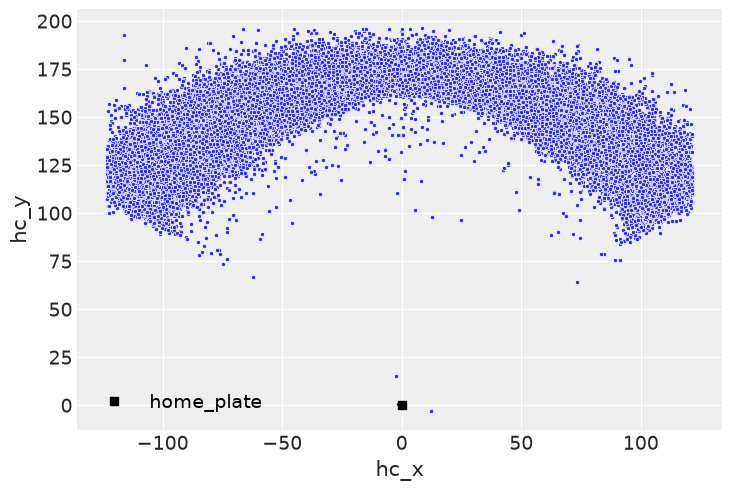

In [23]:
# wanna see the hit coordinates of HRs

hr_balls = batted_balls[(~batted_balls['hc_x'].isna()) & (~batted_balls['hc_y'].isna()) & (batted_balls['events'] == 'home_run')]

plt.figure()
sns.scatterplot(data=hr_balls, x='hc_x', y='hc_y', marker='.')
plt.plot(0, 0, 'ks', label='home_plate')
plt.legend()
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

In [24]:
batted_balls['hc_y'].describe()

count   511293.000000
mean        99.423679
std         38.256088
min        -44.620000
25%         78.040000
50%        102.860000
75%        126.370000
max        196.140000
Name: hc_y, dtype: Float64

In [25]:
batted_balls['hit_distance_sc'].isna().sum()

np.int64(9363)

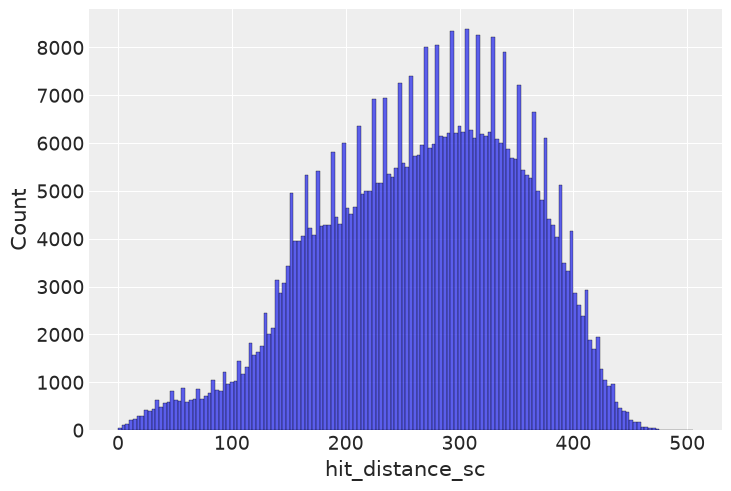

count   501930.000000
mean       268.009145
std         87.913067
min          0.000000
25%        205.000000
50%        275.000000
75%        336.000000
max        505.000000
Name: hit_distance_sc, dtype: float64

In [26]:
plt.figure()
sns.histplot(data=batted_balls, x='hit_distance_sc')
plt.show()

batted_balls['hit_distance_sc'].describe()

obviously there is some discrepancy between `hit_distance_sc` and the translated `hc_y` given the max for one was 505 and the other was 490
* because `hit_distance_sc` is the projected distance when the ball is expected to land and `hc_y` is the estimated point when the ball is fielded, i dont technically have the estimated landing point of the ball - the initial landing point 
* but because i estimated the spray angle of that batted ball using the arctan formula and the hit coord vector, i can use polar coord translation to estimate the landing point coord - i.e., using `hit_distance_sc` as the radial distance from the origin and the spray angle as the angle of rotation - such that X ~ rcos(theta), Y ~ rsin(theta)
* first i gotta deal with the missing `hit_distance_sc`, so we'll just model that since we have exit velo + launch angle + spray angle

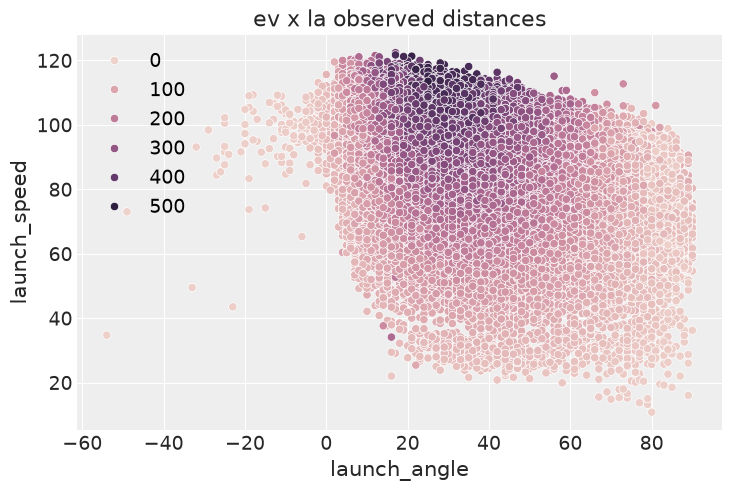

In [27]:
plt.figure()
sns.scatterplot(data=batted_balls[~batted_balls['hit_distance_sc'].isna()], x='launch_angle', y='launch_speed', hue='hit_distance_sc')
plt.title('ev x la observed distances')
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

In [28]:
batted_balls['bb_type'].value_counts()

bb_type
fly_ball      228190
line_drive    218856
popup          64244
Name: count, dtype: int64

In [29]:
batted_balls['bb_type'].isna().sum() ## it only being 3 means im gonna drop them

np.int64(3)

In [30]:
batted_balls = batted_balls[~batted_balls['bb_type'].isna()].reset_index(drop=True)

In [31]:
# because the statcast leaderboards has a minimum threshold of 10 PAs per situation, 
# there's a lot of missing initial coords, so we'll just take the average per situation (good enough proxy)
# this imputation does create some bias towards the fielders with more appearences observed, but it's fine

for pos in range(3, 7):
    x_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'if_fielding_alignment'])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_if_group_means)
    y_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'if_fielding_alignment'])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_if_group_means)

for pos in range(7, 10):
    x_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'of_fielding_alignment'])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_of_group_means)
    y_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state', 'of_fielding_alignment'])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_of_group_means)

## fills the rest of the missing values
for pos in range(3, 7):
    x_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_if_group_means)
    y_if_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_if_group_means)

for pos in range(7, 10):
    x_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_x'].transform('mean')
    batted_balls[f'fielder_{pos}_x'] = batted_balls[f'fielder_{pos}_x'].fillna(x_of_group_means)
    y_of_group_means = batted_balls.groupby(['game_year', 'stand', 'base_state',])[f'fielder_{pos}_y'].transform('mean')
    batted_balls[f'fielder_{pos}_y'] = batted_balls[f'fielder_{pos}_y'].fillna(y_of_group_means)

In [32]:
batted_balls[['fielder_3_name', 'fielder_3', 'fielder_3_x', 'fielder_3_y', 
            'fielder_4_name', 'fielder_4', 'fielder_4_x', 'fielder_4_y',
            'fielder_5_name', 'fielder_5', 'fielder_5_x', 'fielder_5_y',
            'fielder_6_name', 'fielder_6', 'fielder_6_x', 'fielder_6_y',
            'fielder_7_name', 'fielder_7', 'fielder_7_x', 'fielder_7_y',
            'fielder_8_name', 'fielder_8', 'fielder_8_x', 'fielder_8_y',
            'fielder_9_name', 'fielder_9', 'fielder_9_x', 'fielder_9_y',]].isna().sum()

fielder_3_name    0
fielder_3         0
fielder_3_x       0
fielder_3_y       0
fielder_4_name    0
fielder_4         0
fielder_4_x       0
fielder_4_y       0
fielder_5_name    0
fielder_5         0
fielder_5_x       0
fielder_5_y       0
fielder_6_name    0
fielder_6         0
fielder_6_x       0
fielder_6_y       0
fielder_7_name    0
fielder_7         0
fielder_7_x       0
fielder_7_y       0
fielder_8_name    0
fielder_8         0
fielder_8_x       0
fielder_8_y       0
fielder_9_name    0
fielder_9         0
fielder_9_x       0
fielder_9_y       0
dtype: int64

## landing coordinates

In [33]:
batted_balls['hit_distance_sc'].isna().sum() / batted_balls.shape[0]

np.float64(0.01831250366719474)

In [34]:
batted_balls[batted_balls['hit_distance_sc'].isna()]['bb_type'].value_counts(normalize=True)

bb_type
popup        0.892449
fly_ball     0.091103
line_drive   0.016448
Name: proportion, dtype: float64

In [35]:
batted_balls[batted_balls['hit_distance_sc'].isna()]['events'].value_counts(normalize=True)

events
out        0.980882
single     0.008224
double     0.006088
error      0.003952
triple     0.000534
home_run   0.000320
Name: proportion, dtype: float64

the missingness of hit_distance_sc is likely mnar since the outcomes that tend to have a missing recorded hit distance are ground balls or popflies -- likely statcast lost the ball in the dirt or lost it in the air -- so we'll impute these missing values
* because we really only have data at the time of contact, we'll have to use those velocity and angular components to infer the physics of the batted ball -- we're inherently omitting any sort of features that could have an effect on the result of the ball that are post-contact, such as wind, air density, backspin, etc.

In [36]:
# model setup for estimating the missing hit_distance_sc

n_ev_bins = 6

train_df = batted_balls[~batted_balls['hit_distance_sc'].isna()].copy()
test_df = batted_balls[batted_balls['hit_distance_sc'].isna()].copy()

## creates bins of ev
train_df['ev_bin'] = (train_df
                      .groupby('bb_type')['launch_speed']
                      .transform(lambda x: pd.qcut(x, q=n_ev_bins, labels=False, duplicates='drop'))
                      )
## this is to stratify the train/val split so that the distribution of bb_type and ev_bin is preserved
train_df['strat_key'] = train_df['bb_type'].astype(str) + '_' + train_df['ev_bin'].astype(str)

train_, val_ = train_test_split(train_df, test_size=0.2, stratify=train_df['strat_key'], random_state=42)
train_ = train_.drop(columns=['ev_bin', 'strat_key'])
val_ = val_.drop(columns=['ev_bin', 'strat_key'])

X_train = train_[['launch_speed', 'launch_angle', 'spray_angle']].to_numpy(dtype=float)
y_train = train_['hit_distance_sc'].to_numpy(dtype=float)

X_val = val_[['launch_speed', 'launch_angle', 'spray_angle']].to_numpy(dtype=float)
y_val = val_['hit_distance_sc'].to_numpy(dtype=float)

## scaling the train + val set
X_mean = X_train.mean(axis=0)
X_std = np.sqrt(X_train.var(axis=0))

X_train = (X_train - X_mean) / X_std
X_val = (X_val - X_mean) / X_std

In [37]:
X_train[:, :-1]

array([[ 0.10739198,  0.56713501],
       [ 0.88769819, -0.81219222],
       [ 0.36749405,  2.06140618],
       ...,
       [-0.33153027, -0.63977631],
       [ 0.92021095, -0.52483238],
       [-0.80296528,  0.73955092]], shape=(401541, 2))

In [38]:
def distance_model(X_train, y_train, model_name, train_subset):
    """
    trains each model to estimate the batted ball distance
    """
    if model_name == 'gam':
        best_gam = None
        best_gcv = float('inf')
        warnings.filterwarnings("ignore", category=RuntimeWarning)

        ## ev x la features
        if train_subset == 'ev x la':
            spline_candidates = [(i, i) for i in range (4, 11)]
            for splines in spline_candidates:
                try:
                    gam = LinearGAM(te(0, 1, n_splines=splines)).fit(X_train, y_train)
                    gcv = gam.statistics_['GCV']
                    if not np.isnan(gcv) and gcv < best_gcv:
                        best_gcv = gcv
                        best_gam = gam
                except Exception:
                    continue
        
        ## ev x la x sa features
        else:
            spline_candidates = [(i, i, i) for i in range (4, 11)]
            for splines in spline_candidates:
                try:
                    gam = LinearGAM(te(0, 1, 2, n_splines=splines)).fit(X_train, y_train)
                    gcv = gam.statistics_['GCV']
                    if not np.isnan(gcv) and gcv < best_gcv:
                        best_gcv = gcv
                        best_gam = gam
                except Exception:
                    continue

        return best_gam

    elif model_name == 'lr':
        lr_model = sm.OLS(y_train, sm.add_constant(X_train, has_constant='add')).fit()
        print(lr_model.summary())
        return lr_model

    elif model_name == 'xgb':
        xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
        xgb_model.fit(X_train, y_train)
        return xgb_model
    
    elif model_name == 'rf':
        rf_model = RandomForestRegressor(random_state=42)
        rf_model.fit(X_train, y_train)
        return rf_model
        
    else:
        return None

In [39]:
# model results on the validation set -> model selection and evaluation

model_val_results = {}
val_predictions = {}
for model in ['gam', 'lr', 'xgb', 'rf']:
    for train_group in ['ev x la', 'ev x la x sa']:
        print(f'{model}, {train_group}')

        if train_group == 'ev x la':
            X_tr = X_train[:, :-1]
            X_v = X_val[:, :-1]
        else:
            X_tr = X_train
            X_v = X_val

        trained_model = distance_model(X_tr, y_train, model, train_group)

        if model == 'lr':
            train_pred = trained_model.predict(sm.add_constant(X_tr, has_constant='add'))
            val_pred = trained_model.predict(sm.add_constant(X_v, has_constant='add'))
        else:
            train_pred = trained_model.predict(X_tr)
            val_pred = trained_model.predict(X_v)

        ## evaluation metrics
        train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
        train_r2 = r2_score(y_train, train_pred)

        val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
        val_r2 = r2_score(y_val, val_pred)

        dict_key = f"{model}_{train_group.replace(' ', '_')}"
        model_val_results[dict_key] = {'model': model, 
                                       'features': train_group, 
                                       'train_rmse': train_rmse, 'train_r2': train_r2, 
                                       'val_rmse': val_rmse, 'val_r2': val_r2
                                       }
        val_predictions[dict_key] = val_pred

model_val_results_df = pd.DataFrame.from_dict(model_val_results, orient='index').reset_index(drop=True)
model_val_results_df

gam, ev x la
gam, ev x la x sa
lr, ev x la
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.333
Model:                            OLS   Adj. R-squared:                  0.333
Method:                 Least Squares   F-statistic:                 1.000e+05
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        11:26:45   Log-Likelihood:            -2.2859e+06
No. Observations:              401541   AIC:                         4.572e+06
Df Residuals:                  401538   BIC:                         4.572e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const    

,model,features,train_rmse,train_r2,val_rmse,val_r2
0,gam,ev x la,20.157340,0.947382,20.122234,0.947780
1,gam,ev x la x sa,17.870347,0.958644,17.919389,0.958588
2,lr,ev x la,71.791276,0.332560,72.077624,0.329986
3,lr,ev x la x sa,71.746405,0.333394,72.047180,0.330551
4,xgb,ev x la,20.031336,0.948038,20.153564,0.947617
5,xgb,ev x la x sa,17.476543,0.960447,17.808072,0.959101
6,rf,ev x la,19.304625,0.951739,20.717603,0.944644
7,rf,ev x la x sa,7.204546,0.993278,19.352593,0.951698


xgboost with ev x la x sa as the features performed the best on the validation set and it didn't overfit that much as the train error is identical to the validation error, so we'll use it
* an error of roughly 17 ft on average seems high but this is across all batted balls that go in the air, where balls that travel far will have higher error solely due to components that the data doesn't include has an effect - therefore can't include in the model - such as batted ball spin, air/wind conditions of that park on that day, time, etc. -> i could also add the venue as an adjustment - because of coors and t-mobile - however i wanted to focus solely on the conditions that come from the batted ball itself and not external factors that affect ball flight

In [40]:
# trains our best model on the val set

trained_model = distance_model(X_train, y_train, 'xgb', 'ev x la x sa')
train_pred = trained_model.predict(X_train)
val_pred = trained_model.predict(X_val)

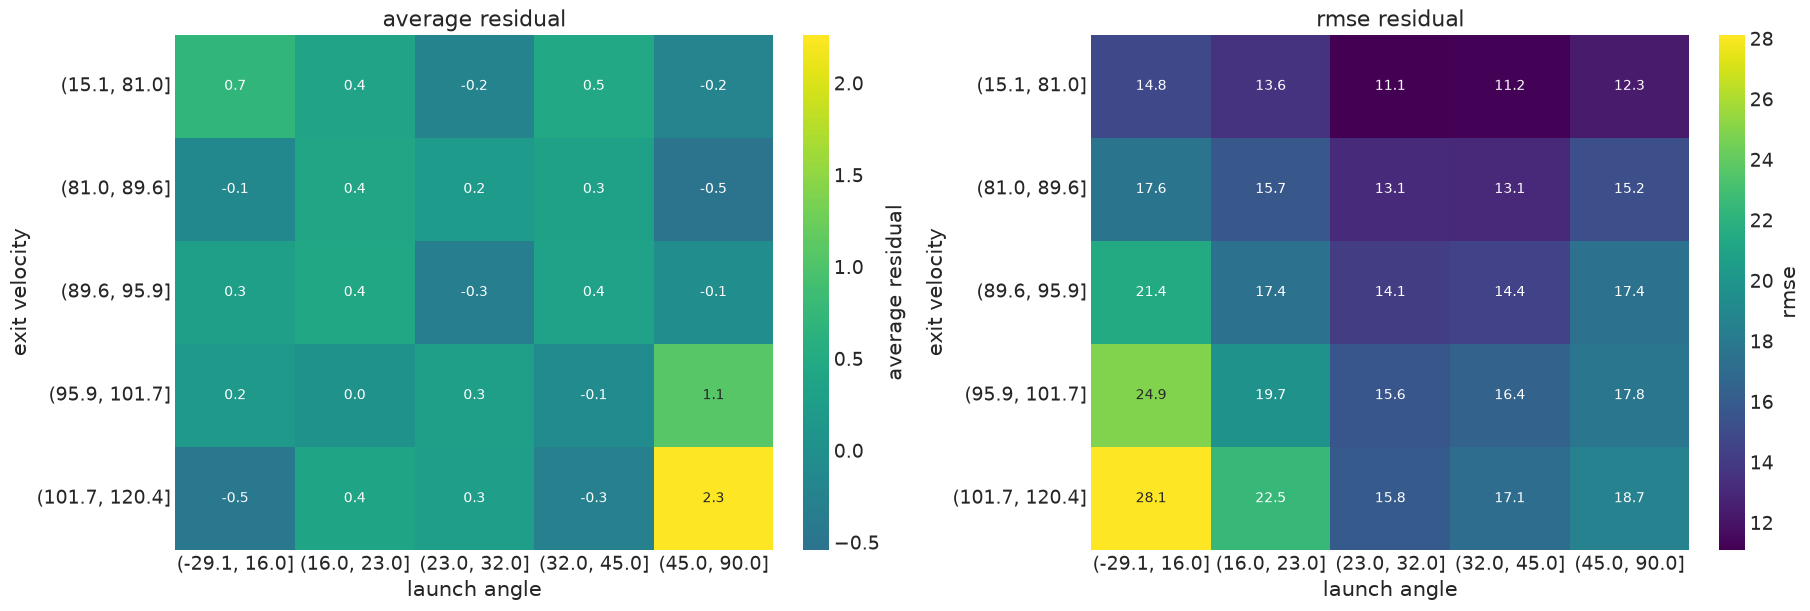

In [41]:
# residual analysis on the validation set

model_residuals = y_val - val_pred
model_diagnostics = pd.DataFrame({'ev': X_val[:, 0], 
                                  'la': X_val[:, 1], 
                                  'sa': X_val[:, 2], 
                                  'y_true': y_val, 
                                  'y_pred': val_pred, 
                                  'resid': model_residuals, 
                                  'sq_resid': model_residuals**2
                                  })

## inverse transforms back to original scale b/c it's in z-scores
## creates bins to create 5 groups based on the percentiles (min, 20th, ..., 80th, max)
for i, col in enumerate(['ev', 'la', 'sa']):
    model_diagnostics[col] = model_diagnostics[col] * X_std[i] + X_mean[i]
    model_diagnostics[f'{col}_bin'] = pd.qcut(model_diagnostics[col], q=5, duplicates='drop', precision=1)

## average residual
mean_resid = model_diagnostics.groupby(['ev_bin', 'la_bin'], observed=True)['resid'].mean().unstack()

## rmse
rmse_resid = np.sqrt(model_diagnostics.groupby(['ev_bin', 'la_bin'], observed=True)['sq_resid'].mean().unstack())

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(mean_resid, annot=True, fmt='.1f', cmap='viridis', center=0, ax=axes[0], cbar_kws={'label': 'average residual'})
axes[0].set_title('average residual')
axes[0].set_xlabel('launch angle')
axes[0].set_ylabel('exit velocity')
sns.heatmap(rmse_resid, annot=True, fmt='.1f', cmap='viridis', ax=axes[1], cbar_kws={'label': 'rmse'})
axes[1].set_title('rmse residual')
axes[1].set_xlabel('launch angle')
axes[1].set_ylabel('exit velocity')
plt.show()

* im not sure if i want to actually impute those missing hit distances just because it seems that there's too much of an error on certain batted balls (barrels and flyballs/popflies)

In [42]:
batted_balls = batted_balls[~batted_balls['hit_distance_sc'].isna()].reset_index(drop=True)

In [43]:
# estimates the landing coordinate of the batted ball - where the ball would land on the field for the first time

batted_balls['X_coord'] = batted_balls['hit_distance_sc'] * np.cos(np.radians(90 - batted_balls['spray_angle']))
batted_balls['Y_coord'] = batted_balls['hit_distance_sc'] * np.sin(np.radians(90 - batted_balls['spray_angle']))

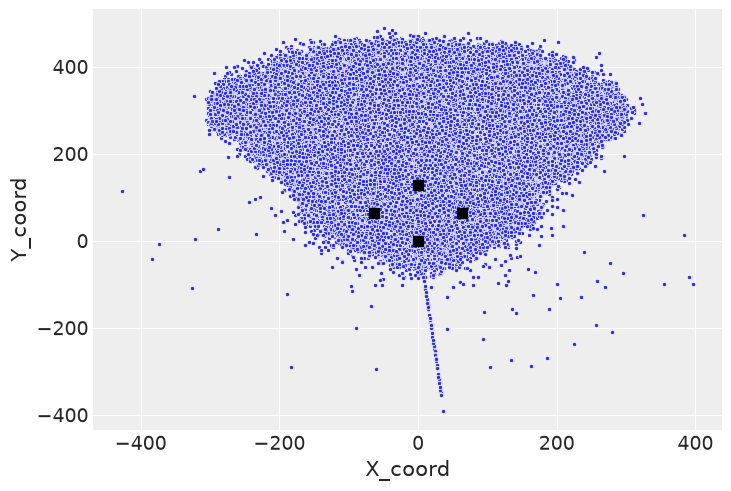

In [44]:
## the foul lines to be visualized
lf_x_values = np.linspace(0, -300)
lf_foul_line = -lf_x_values
rf_x_values = np.linspace(0, 300)
rf_foul_line = rf_x_values

## the coords of each base
base_xy = 90 * np.sin(np.radians(45)) 
bases_x = [0, base_xy, 0, -base_xy]
bases_y = [0, base_xy, np.sqrt(90**2 + 90**2), base_xy]

plt.figure()
sns.scatterplot(data=batted_balls, x='X_coord', y='Y_coord', marker='.')
plt.scatter(bases_x, bases_y, color="black", marker="s", s=50, label="Bases", zorder=5)
plt.show()

* the landing coordinates look pretty reasonable but we should understand the distribution of batted ball types across these coordinates to visually validate the coords

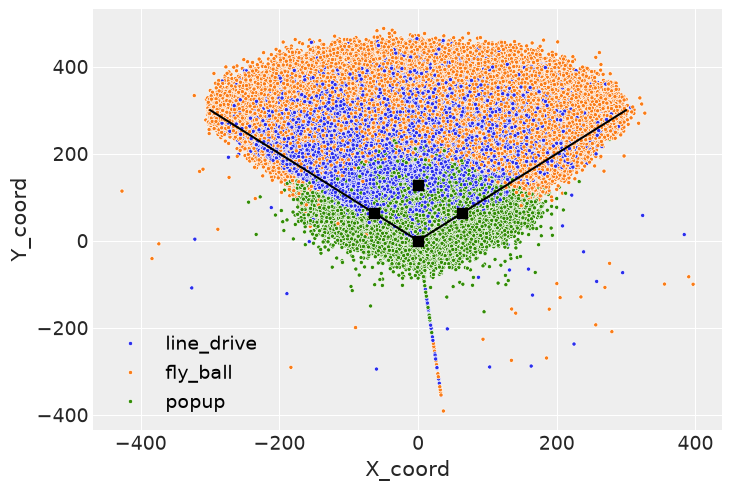

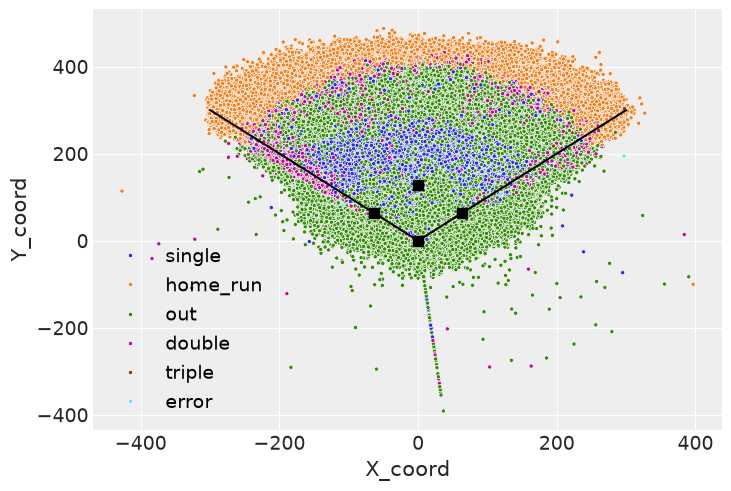

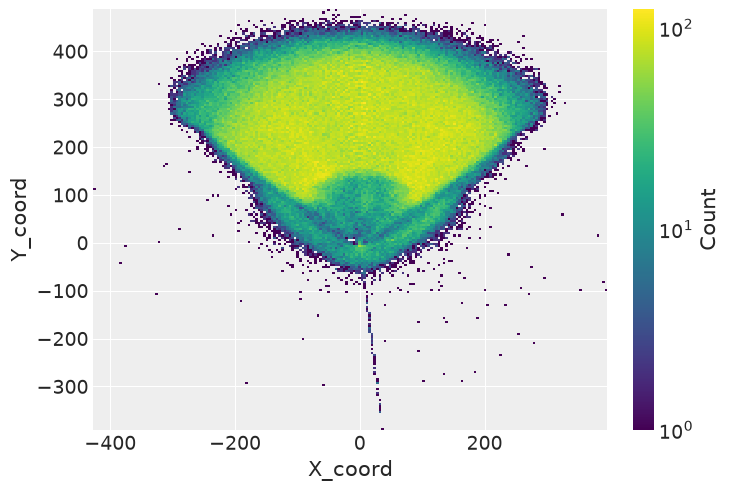

In [45]:
plt.figure()
sns.scatterplot(data=batted_balls, x='X_coord', y='Y_coord', hue='bb_type', marker='.')
plt.plot(lf_x_values, lf_foul_line, c='black',)
plt.plot(rf_x_values, rf_foul_line, c='black')
plt.scatter(bases_x, bases_y, color='black', marker='s', s=50, zorder=5)
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

plt.figure()
sns.scatterplot(data=batted_balls, x='X_coord', y='Y_coord', hue='events', marker='.')
plt.plot(lf_x_values, lf_foul_line, c='black',)
plt.plot(rf_x_values, rf_foul_line, c='black')
plt.scatter(bases_x, bases_y, color='black', marker='s', s=50, zorder=5)
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

plt.figure()
plt.hist2d(batted_balls['X_coord'], batted_balls['Y_coord'], bins=200, norm=LogNorm())
plt.xlabel('X_coord')
plt.ylabel('Y_coord')
plt.colorbar(label='Count')
plt.show()

* some thoughts are that there are a number of these batted balls - especially hrs - that are outside of the boundaries of the foul lines. because we're using polar coords to estimate the ball's landing coords, we're essentially projecting everything onto an "average" circular field. statcast's estimated `hit_distance_sc` is park-independent, so this circular arc around the hrs is unavoidable

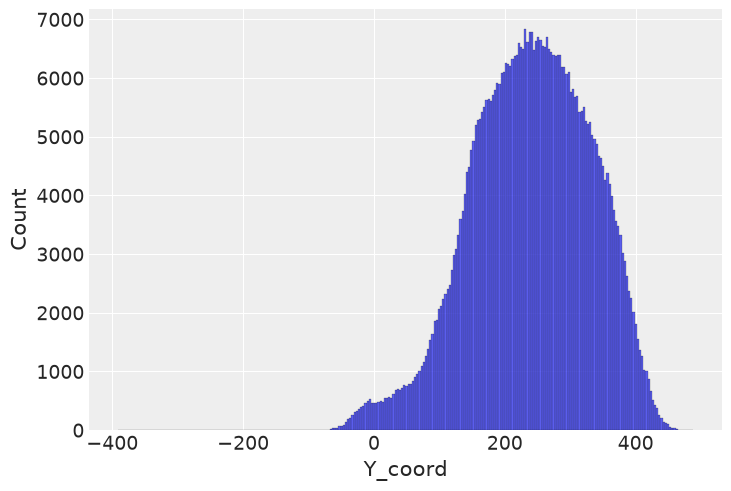

count   501927.000000
mean       239.783500
std         91.643974
min       -391.307883
25%        177.022888
50%        243.049530
75%        308.528677
max        487.480877
Name: Y_coord, dtype: float64

In [46]:
plt.figure()
sns.histplot(data=batted_balls, x='Y_coord')
plt.show()

batted_balls['Y_coord'].describe()

* i don't want to deal with these weird negative Y_coords so i'll just omit those because i care more about outfield defense regardless

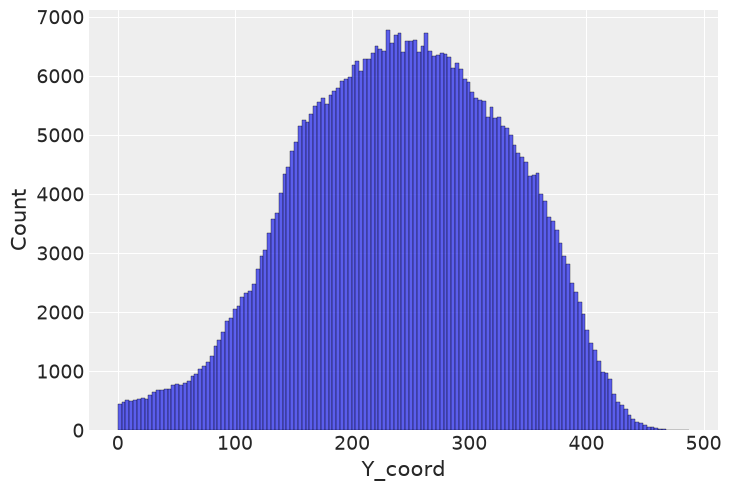

In [47]:
plt.figure()
sns.histplot(x=batted_balls[batted_balls['Y_coord'] > 0].reset_index(drop=True)['Y_coord'])
plt.show()

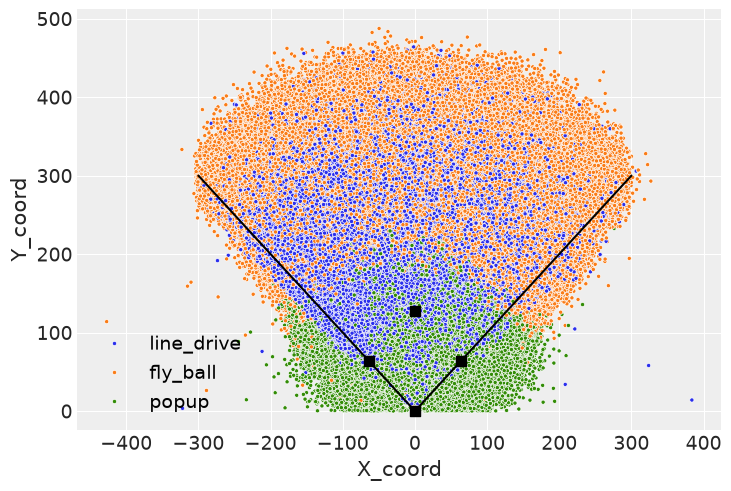

In [48]:
plt.figure()
sns.scatterplot(data=batted_balls[batted_balls['Y_coord'] > 0], x='X_coord', y='Y_coord', hue='bb_type', marker='.')
plt.plot(lf_x_values, lf_foul_line, c='black',)
plt.plot(rf_x_values, rf_foul_line, c='black')
plt.scatter(bases_x, bases_y, color='black', marker='s', s=50, zorder=5)
legend = plt.legend()
for text in legend.get_texts():
    text.set_color('black')
plt.show()

In [49]:
batted_balls = batted_balls[batted_balls['Y_coord'] > 0].reset_index(drop=True).copy()

## distance to landing coordinate

In [50]:
# handles all of the credit - who got the out and everything

batted_balls['is_out'] = (batted_balls['events'] == 'out').astype(int)
batted_balls['out_credit_pos'] = batted_balls['hit_location'].where(batted_balls['is_out'] == 1, np.nan)

batted_balls['out_credit_name'] = None
for pos in range(3, 10):
    mask = batted_balls['out_credit_pos'] == pos
    batted_balls.loc[mask, 'out_credit_name'] = batted_balls.loc[mask, f'fielder_{pos}_name']

batted_balls['out_credit_x'] = None
for pos in range(3, 10):
    mask = batted_balls['out_credit_pos'] == pos
    batted_balls.loc[mask, 'out_credit_x'] = batted_balls.loc[mask, f'fielder_{pos}_x']

batted_balls['out_credit_y'] = None
for pos in range(3, 10):
    mask = batted_balls['out_credit_pos'] == pos
    batted_balls.loc[mask, 'out_credit_y'] = batted_balls.loc[mask, f'fielder_{pos}_y']

In [51]:
batted_balls['playid'] = np.arange(len(batted_balls))

In [52]:
# calculating the straight line distance needed from each position to the estimated initial ball loc

def euclidean_dist(ball_x, ball_y, player_x, player_y):
    """
    finds the straight-line distance (euclidean distance) between two coordinates
    """
    return np.sqrt((player_x - ball_x)**2 + (player_y - ball_y)**2)

distance_coords = batted_balls.copy()

In [53]:
for pos in range(3, 10):
    distance_coords[f'dist_to_ball_{pos}'] = euclidean_dist(distance_coords['X_coord'], distance_coords['Y_coord'], \
                                                            distance_coords[f'fielder_{pos}_x'], distance_coords[f'fielder_{pos}_y'])

* okay so there shouldn't be balls in play where the center field had to travel 300 ft to get to the ball and make the out

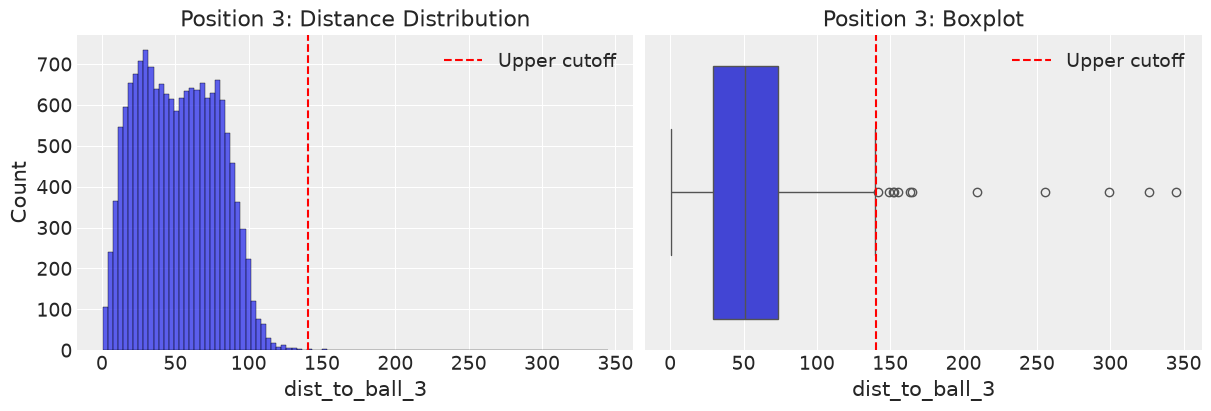

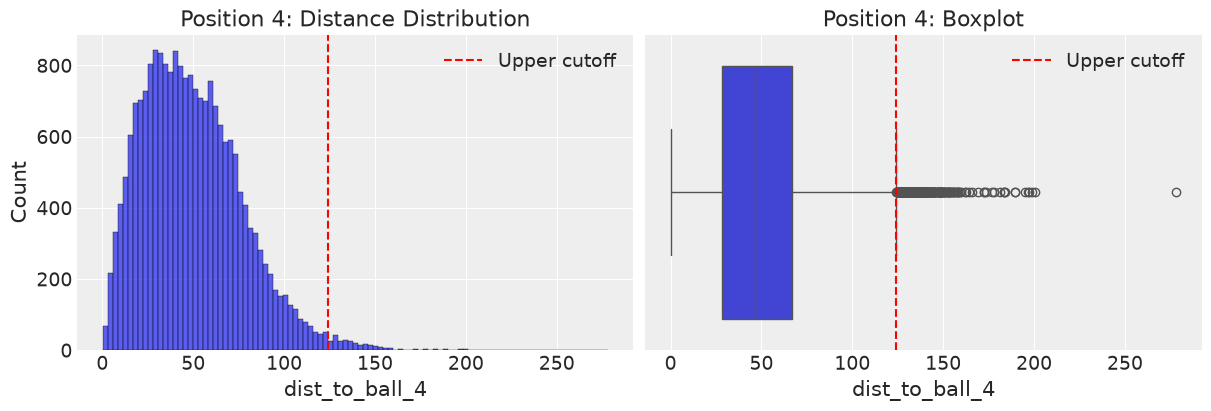

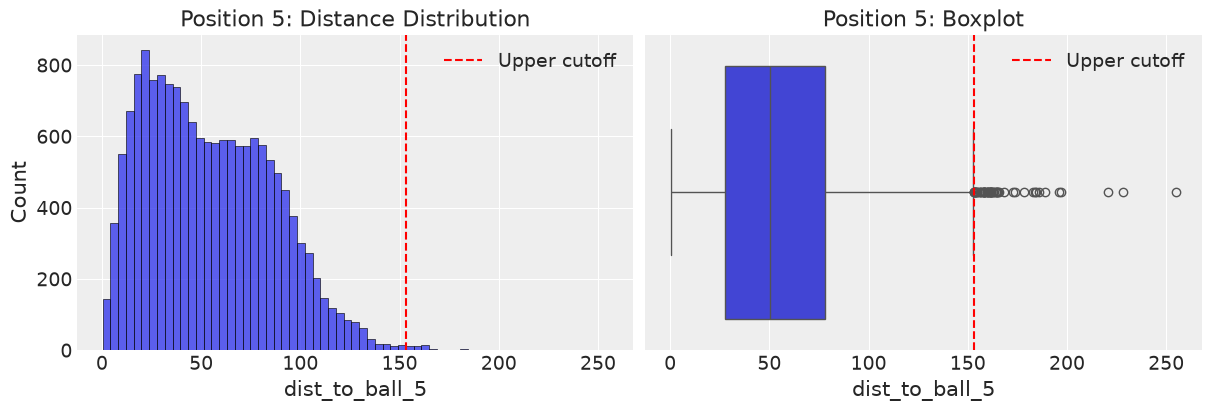

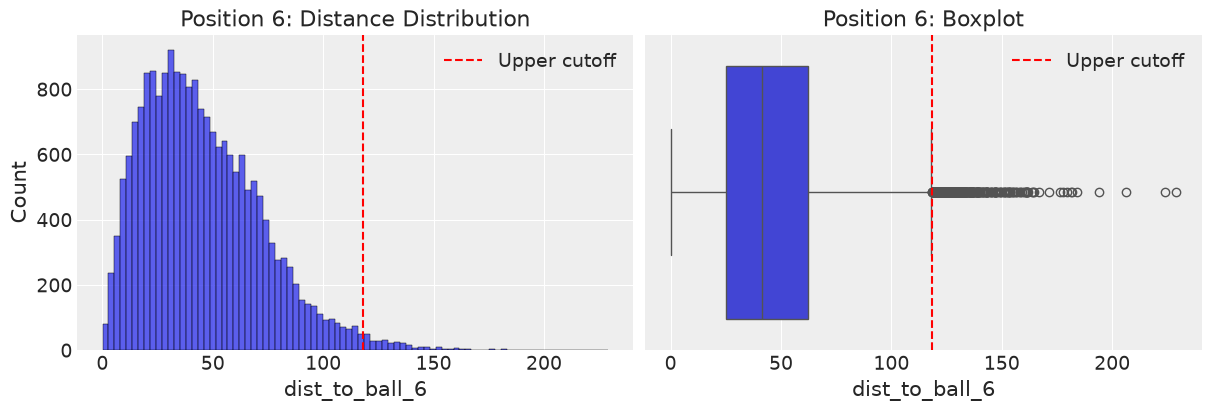

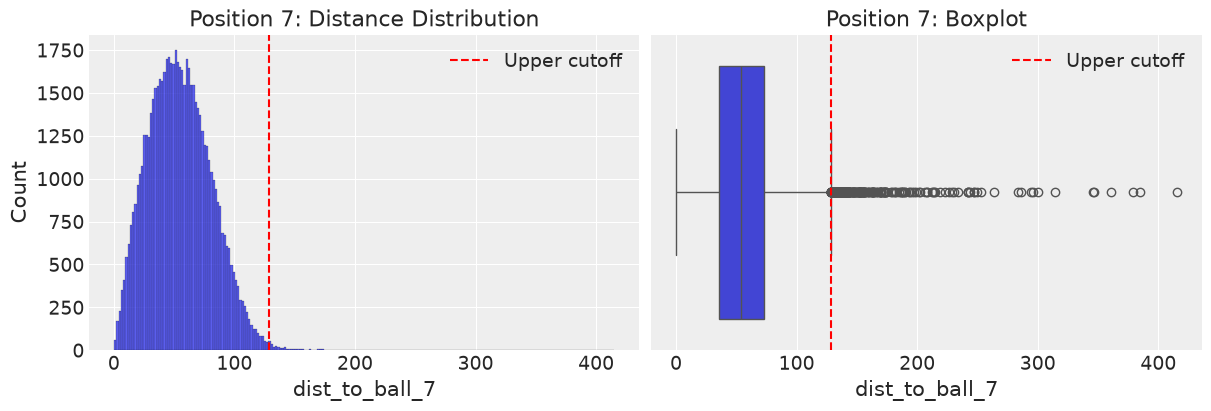

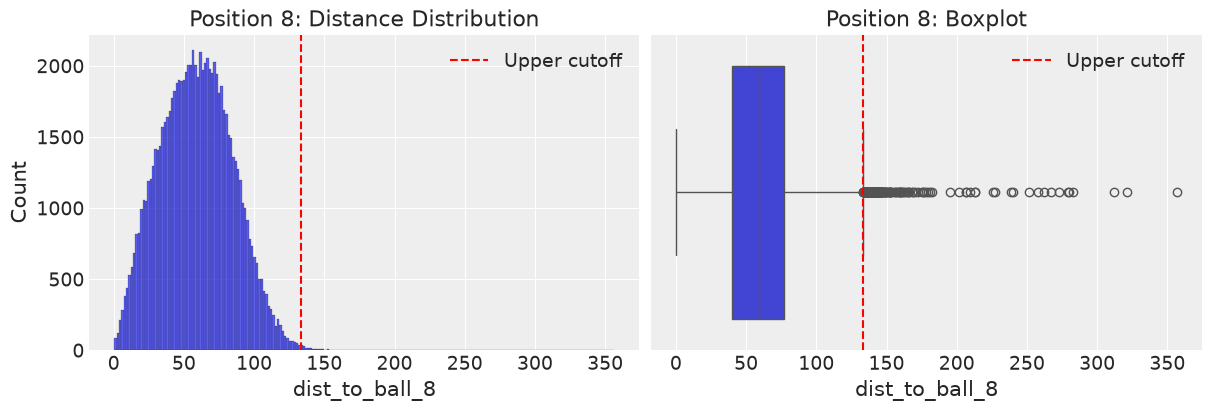

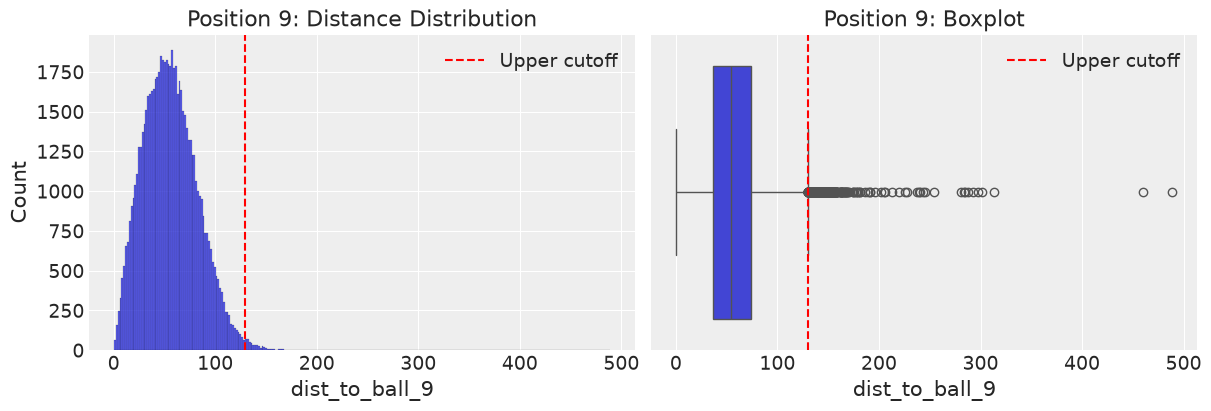

In [54]:
def plot_distance_to_ball(pos):
    """
    plots the distances to ball for the plays that were outs
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    x = distance_coords.loc[distance_coords['out_credit_pos'] == pos, f'dist_to_ball_{pos}']

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    upper_cutoff = q3 + 1.5 * iqr

    sns.histplot(x=x, ax=axes[0])
    axes[0].axvline(upper_cutoff, color='red', linestyle='--', label='Upper cutoff')
    axes[0].set_title(f'Position {pos}: Distance Distribution')
    axes[0].set_xlabel(f'dist_to_ball_{pos}')
    axes[0].legend()

    sns.boxplot(x=x, ax=axes[1])
    axes[1].axvline(upper_cutoff, color='red', linestyle='--', label='Upper cutoff')
    axes[1].set_title(f'Position {pos}: Boxplot')
    axes[1].set_xlabel(f'dist_to_ball_{pos}')
    axes[1].legend()

    plt.show()

    distance_coords[distance_coords['out_credit_pos'] == pos][f'dist_to_ball_{pos}'].describe()

for pos in range(3, 10):
    plot_distance_to_ball(pos)

* so for the most part, the distances don't seem too bad, it's just those weird outliers - let's just omit those ones that are probably a result of the weird spray angles

In [55]:
# calculates distance to ball upper cutoff for each position

cutoffs = {}
for pos in range(3, 10):
    
    x = distance_coords.loc[distance_coords['out_credit_pos'] == pos, f'dist_to_ball_{pos}']

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    cutoffs[pos] = q3 + 1.5 * iqr

valid_pos = distance_coords['out_credit_pos'].isin(range(3, 10))
distance_coords.loc[valid_pos, 'dist_to_ball'] = distance_coords.loc[valid_pos].apply(lambda x: x[f"dist_to_ball_{int(x['out_credit_pos'])}"], axis=1)
distance_coords['upper_cutoff'] = distance_coords['out_credit_pos'].map(cutoffs)

# filters out plays above the position-specific cutoff
distance_coords = distance_coords[~valid_pos | (distance_coords['dist_to_ball'] < distance_coords['upper_cutoff'])].copy()

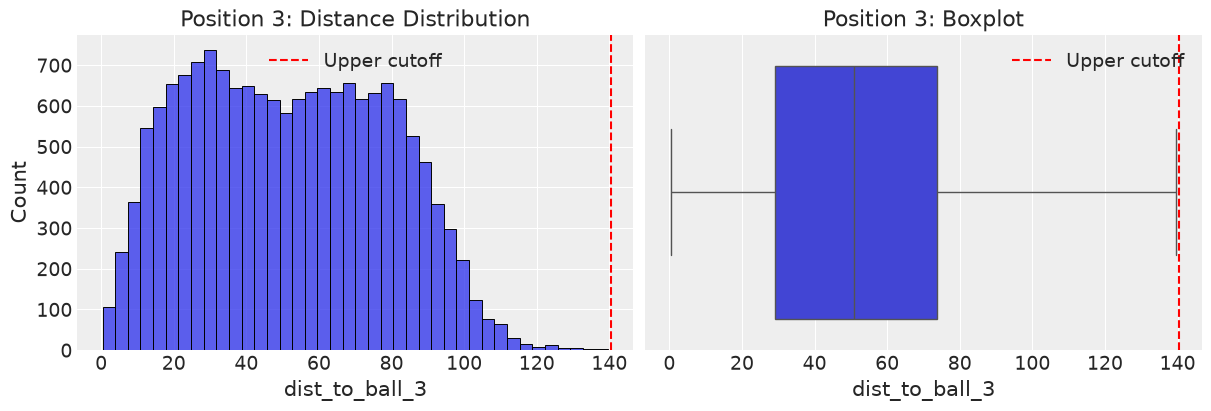

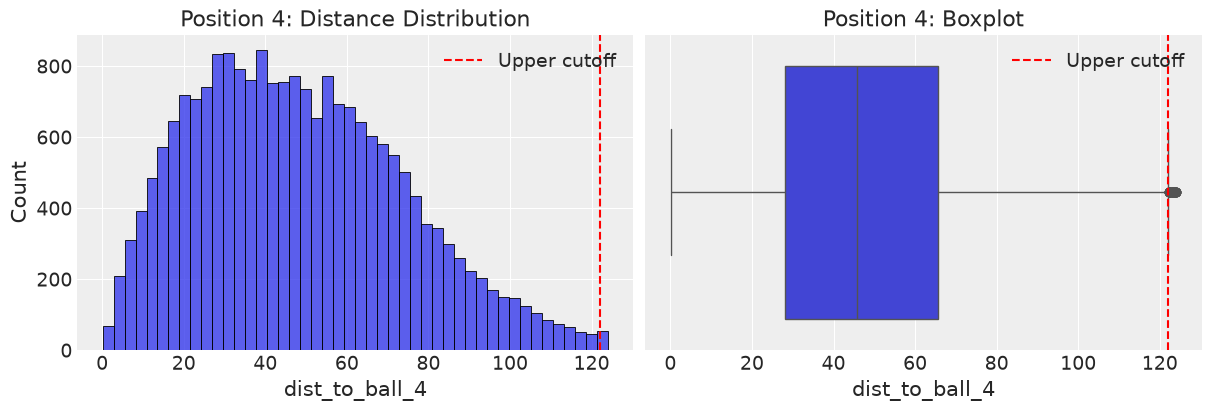

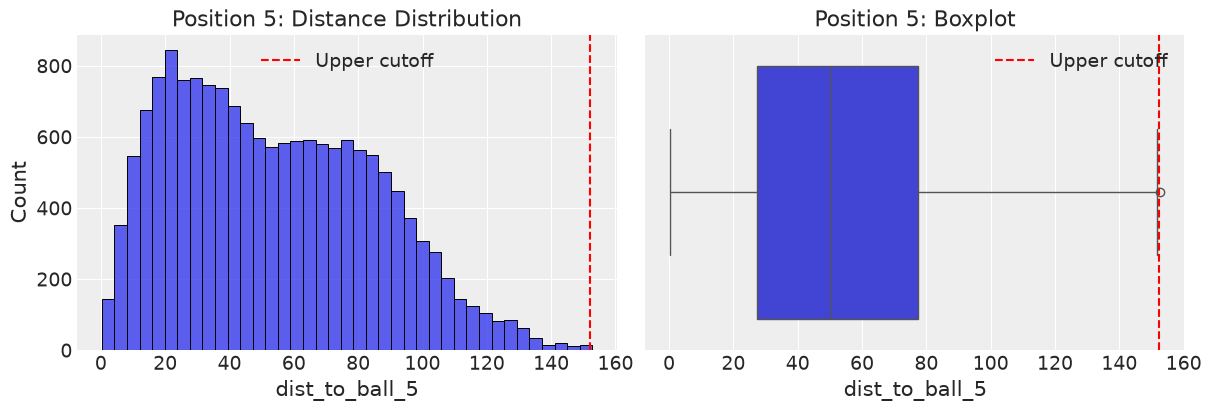

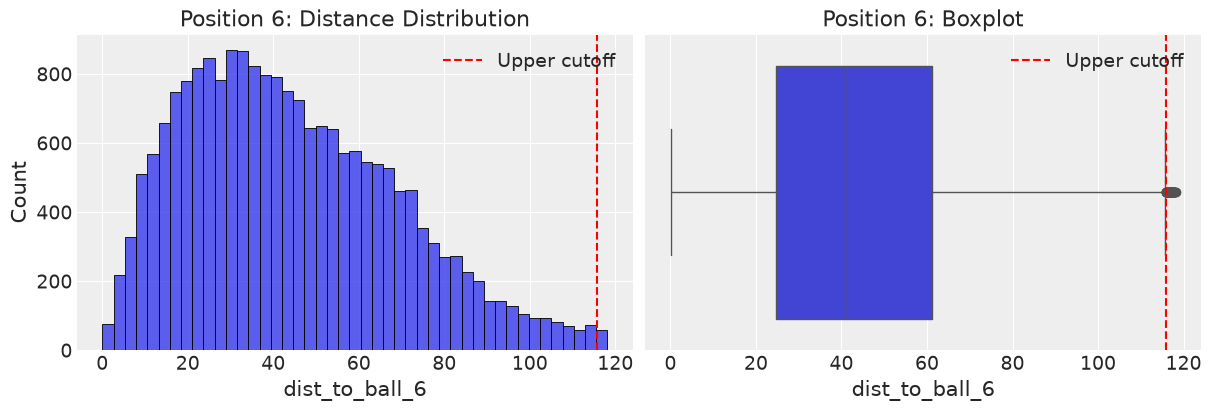

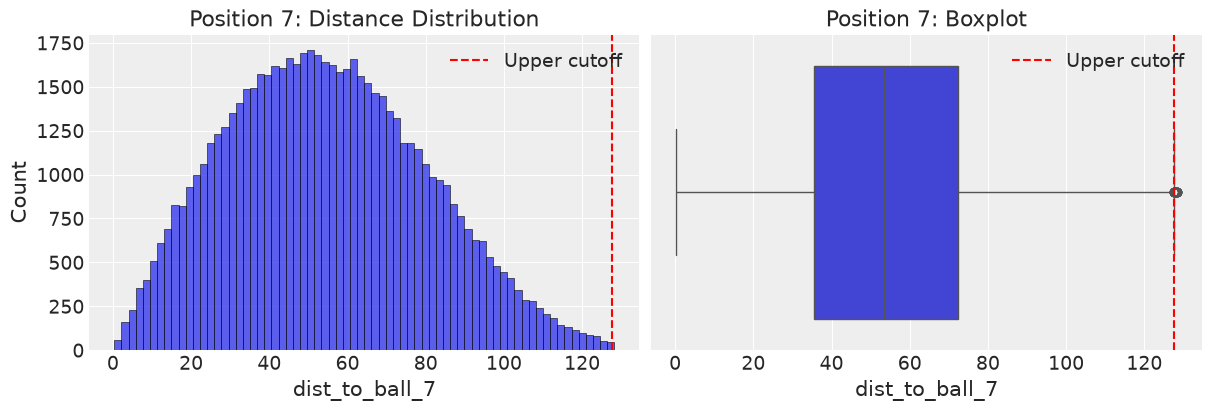

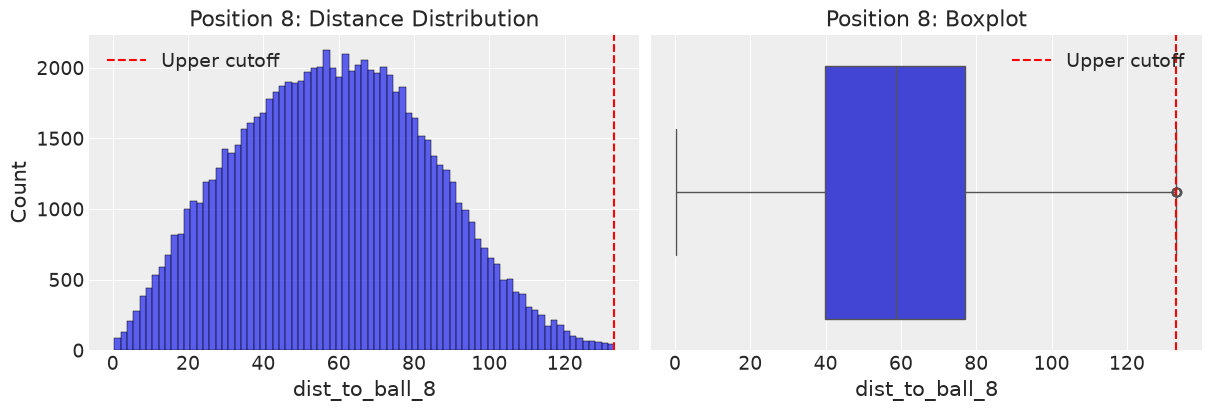

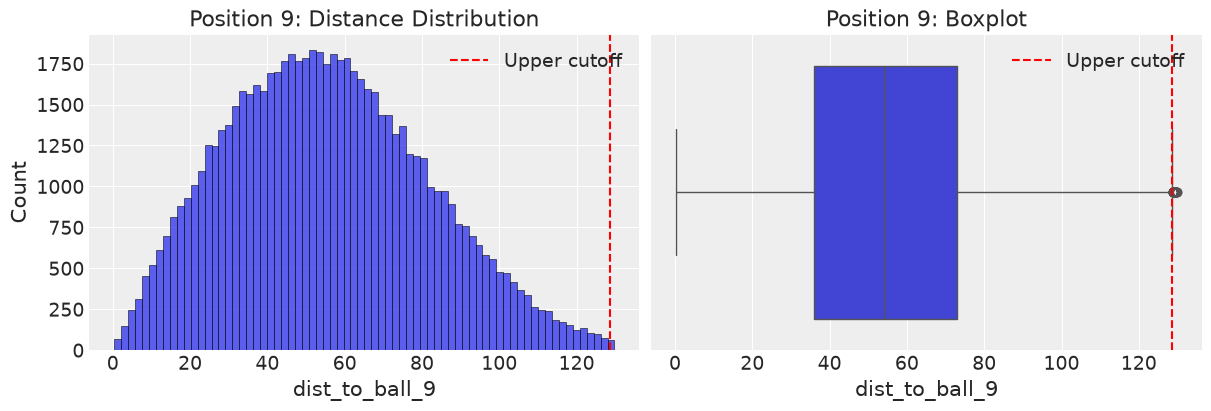

In [56]:
for pos in range(3, 10):
    plot_distance_to_ball(pos)

## hang time

In [57]:
# https://www.firgelliauto.com/blogs/engineering-calculators/time-of-flight-projectile-motion-calculator?srsltid=AfmBOooJX8HBVgMLoAKkaWmu9hvyOXesl4FXw_6mesHBbd31hfyhN9om

def calculate_hang_time(ev, la):
    """
    uses the time of flight for a projectile launched and landing on flat ground calculation
    """
    mph_to_ms = 0.44704
    v_0 = ev * mph_to_ms
    theta = np.radians(la)
    g = 9.81
    return (2 * v_0 * np.sin(theta)) / g

* to evaluate hang time, we're gonna treat the ball in play as if it were in a vacuum. why? because we're using statcast data and i'm not a physics person, so this is the best i got with what i got - but it should be fine as the relationships underlying hangtime with out probability should still be there, but at least the framework would be there

In [58]:
distance_coords['hang_time'] = distance_coords.apply(lambda x: calculate_hang_time(x['launch_speed'], x['launch_angle']), axis=1)

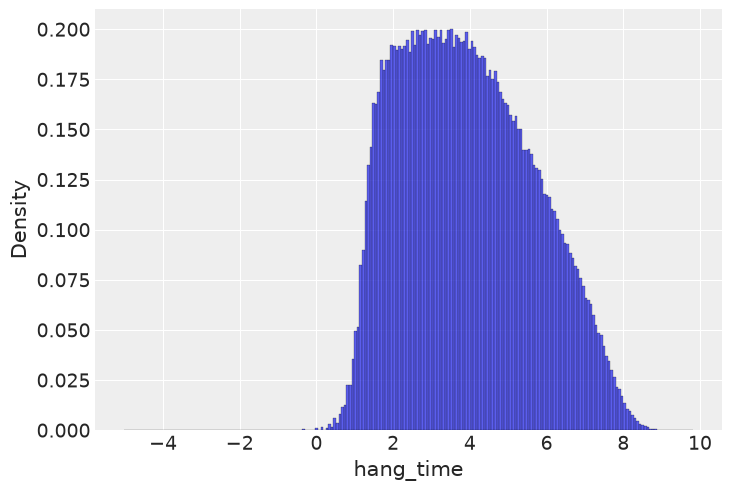

In [59]:
plt.figure()
sns.histplot(data=distance_coords, x='hang_time', stat='density', )
plt.show()

## angle to the ball

In [60]:
def direction_angle(player_coord_x, player_coord_y, ball_coord_x, ball_coord_y):
    """
    finds the direction angle between every outfielder's starting position and the ball's catch point
    where 0º is looking towards home (in front), and 180º is looking towards the outfield wall (towards the back)
    """
    theta = np.degrees((math.atan2(ball_coord_y - player_coord_y, ball_coord_x - player_coord_x)))
    if theta < 0:
        theta = theta + 360
    return theta

direction_angle(0.000, 323.000, 71.665659, 304.685138)

np.float64(345.6643359110575)

In [61]:
for pos in np.arange(3, 10):
    distance_coords[f'direction_angle_{pos}'] = distance_coords.apply(lambda x: direction_angle(x[f'fielder_{pos}_x'], x[f'fielder_{pos}_y'], \
                                                                                                x[f'X_coord'], x['Y_coord']), axis=1)

## distance to the wall

In [62]:
distance_coords['is_hr'] = (distance_coords['events'] == 'home_run').astype(int)

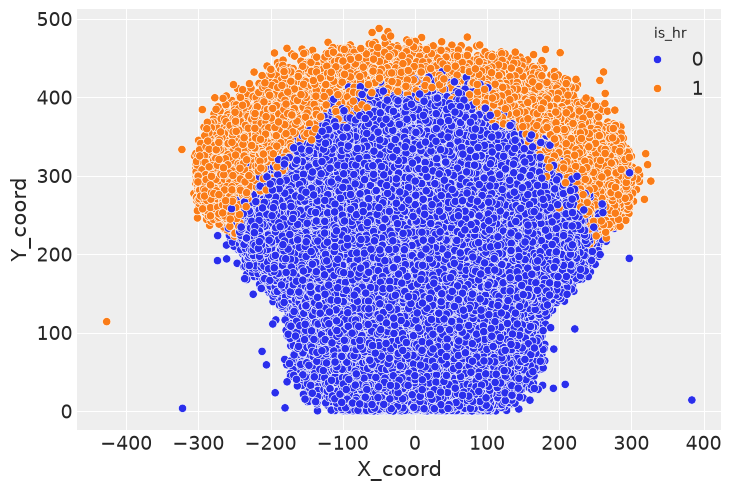

In [63]:
plt.figure()
sns.scatterplot(data=distance_coords, x='X_coord', y='Y_coord', hue='is_hr')
plt.show()

In [64]:
distance_coords[(distance_coords['is_hr'] == 1) & (distance_coords['Y_coord'] < 200)]

,game_pk,game_year,game_date,description,events,bb_type,p_throws,player_name,batter,stand,release_speed,release_pos_x,release_pos_y,release_pos_z,release_extension,vx0,vy0,vz0,ax,ay,az,plate_x,plate_z,on_1b,on_2b,on_3b,runners_on,base_state,launch_speed,launch_angle,effective_speed,hit_distance_sc,hc_x,hc_y,hit_location,if_fielding_alignment,of_fielding_alignment,if_shifted,of_shifted,fielding_team,fielder_3_name,fielder_3,fielder_3_x,fielder_3_y,fielder_4_name,fielder_4,fielder_4_x,fielder_4_y,fielder_5_name,fielder_5,fielder_5_x,fielder_5_y,fielder_6_name,fielder_6,fielder_6_x,fielder_6_y,fielder_7_name,fielder_7,fielder_7_x,fielder_7_y,fielder_8_name,fielder_8,fielder_8_x,fielder_8_y,fielder_9_name,fielder_9,fielder_9_x,fielder_9_y,venue_id,venue_name,spray_angle,X_coord,Y_coord,is_out,out_credit_pos,out_credit_name,out_credit_x,out_credit_y,playid,dist_to_ball_3,dist_to_ball_4,dist_to_ball_5,dist_to_ball_6,dist_to_ball_7,dist_to_ball_8,dist_to_ball_9,dist_to_ball,upper_cutoff,hang_time,direction_angle_3,direction_angle_4,direction_angle_5,direction_angle_6,direction_angle_7,direction_angle_8,direction_angle_9,is_hr
9171,567592,2019,2019-06-26,hit_into_play,home_run,fly_ball,L,"LeBlanc, Wade",592325,L,83.100000,2.880000,54.200000,5.340000,6.300000,-6.303563,-120.908937,-3.017699,2.401927,20.822848,-24.307814,0.244842,1.882075,0,0,0,0,000,79.100000,32.000000,83.500000,251.000000,-74.930000,73.590000,7,Standard,Standard,0,0,SEA,"Vogelbach, Daniel",596129,78.727083,90.565150,"Strange-Gordon, Dee",543829,50.137496,145.609861,"Beckham, Tim",542921,-44.934080,105.858058,"Crawford, J.P.",641487,-21.154311,150.520746,"Williamson, Mac",607776,-132.111235,259.282899,"Smith, Mallex",605480,0.000000,321.000000,"Santana, Domingo",570267,128.881117,264.245450,32,American Family Field,-45.516929,-179.077835,175.875322,0,<NA>,None,None,None,9171,271.553313,231.204814,151.317429,159.945909,95.721916,230.499551,320.387259,NaN,NaN,3.820266,161.690115,172.478209,152.437380,170.879016,240.616246,219.021309,196.011057,1
21492,716462,2023,2023-09-23,hit_into_play,home_run,line_drive,L,"Falter, Bailey",670770,L,84.200000,1.360000,53.150000,5.800000,7.400000,-3.184064,-122.707136,-3.612502,0.130370,21.083590,-22.914448,-0.018103,2.302278,0,0,0,0,000,100.100000,5.000000,86.400000,121.000000,95.240000,92.510000,9,Standard,Standard,0,0,PIT,"Rivas III, Alfonso",663845,71.123478,101.574853,"Bae, Ji Hwan",678225,48.184087,139.936749,"Triolo, Jared",669707,-47.782455,97.968551,"Williams, Alika",675961,-13.421984,153.413984,"Reynolds, Bryan",668804,-134.268867,252.523012,"Suwinski, Jack",669261,-16.747506,319.561451,"Palacios, Joshua",641943,127.208097,272.798644,2602,Great American Ball Park,45.833057,86.794839,84.306915,0,<NA>,None,None,None,21492,23.318946,67.716089,135.268948,121.734131,277.787360,257.032516,192.775422,NaN,NaN,0.795129,312.225028,304.763183,354.203467,325.410804,322.731062,293.755687,257.898799,1
354246,661845,2022,2022-06-15,hit_into_play,home_run,fly_ball,L,"Allard, Kolby",455117,R,82.000000,2.150000,54.580000,5.480000,5.900000,-6.237448,-119.247387,-1.204626,12.521568,22.856143,-25.326176,0.387061,2.654522,0,0,0,0,000,106.800000,28.000000,81.400000,442.000000,-1.500000,0.400000,<NA>,Infield shade,Standard,1,0,TEX,"Lowe, Nathaniel",663993,53.519758,100.656026,"Duran, Ezequiel",677649,-8.059737,153.788948,"Miller, Brad",543543,-70.801070,90.621237,"Semien, Marcus",543760,-53.396824,139.103484,"Calhoun, Kole",594777,-127.630715,273.704952,"Taveras, Leody",665750,16.538162,315.566933,"García, Adolis",666969,137.085696,257.820697,5325,Globe Life Field,-75.068583,-427.075843,113.886892,0,<NA>,None,None,None,354246,480.777691,420.911714,357.033619,374.528885,339.424803,487.307116,582.232929,NaN,NaN,4.569702,178.423037,185.439758,176.263744,183.860578,208.089465,204.447949,194.312476,1
